# Obesity and Fresh Food Access
## New Evidence and Solutions From Geospatial Data
**Saswat Tripathi · ISEF-related research**

This walkthrough connects a public-health research question to a reproducible ML experiment: **does the food environment add predictive value beyond socioeconomic and rural–urban context?**

The notebook inspects the included county data and completed state-held-out experiments. The full training implementation is in `src/model.py`; run `python src/model.py` from the repository root to train again. Outputs below are from executed code cells, not illustrative numbers.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from model import load_data, FEATURE_SETS, grouped_splits

data = load_data(ROOT / "data/processed/county_obesity_2019_model_data.csv")
results = ROOT / "results/portfolio"
print(f"{len(data):,} counties · {data.state.nunique()} state-level groups")
print(data[["obesity_adj_pct", "low_access_share", "poverty_pct", "ba_plus_pct"]].describe().round(3).to_string())

3,110 counties · 49 state-level groups
       obesity_adj_pct  low_access_share  poverty_pct  ba_plus_pct
count         3110.000          3110.000     3110.000     3110.000
mean            35.785             0.244       14.494       21.841
std              4.259             0.186        5.776        9.456
min             16.400             0.000        2.700        0.000
25%             33.400             0.119       10.500       15.300
50%             36.200             0.215       13.500       19.500
75%             38.400             0.323       17.500       25.700
max             51.000             1.000       47.700       77.600


## 1. Inspect the prediction problem

The target is an age-adjusted **county percentage**, so this is regression rather than individual classification. FIPS is a join key and a grouping key, never a model feature. Socioeconomic factors can relate to both food environments and obesity, motivating a controls-only comparison before attributing predictive value to food measures.

Source vintages differ; the data guide records those limitations. The complete-case table is already prepared, so this inspection cannot recover missing counties from the raw merge.

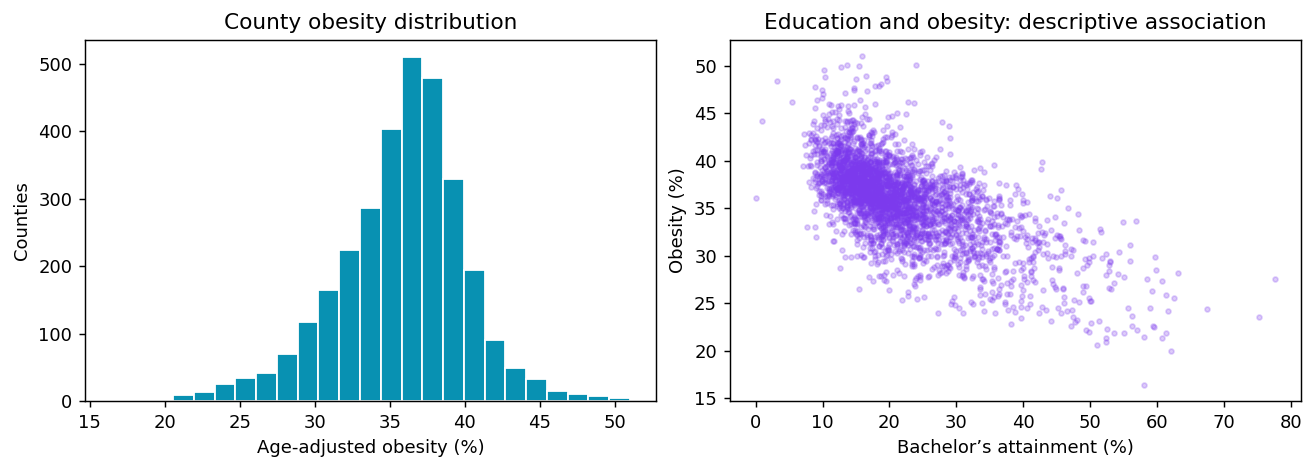

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].hist(data.obesity_adj_pct, bins=25, color="#0891b2", edgecolor="white")
axes[0].set(title="County obesity distribution", xlabel="Age-adjusted obesity (%)", ylabel="Counties")
axes[1].scatter(data.ba_plus_pct, data.obesity_adj_pct, s=7, alpha=0.25, color="#7c3aed")
axes[1].set(title="Education and obesity: descriptive association", xlabel="Bachelor’s attainment (%)", ylabel="Obesity (%)")
plt.show()

## 2. Define comparisons before reading their results

Four feature sets separate access from the composite swamp measure and its component outlet densities. The swamp ratio is not combined with its ingredients in one model. The naive baseline predicts the outer training set’s mean obesity percentage.

**Why ElasticNet?** It offers an interpretable, regularized linear benchmark with correlated socioeconomic measurements. **Why XGBoost?** It tests whether a nonlinear tree ensemble extracts predictive structure that this linear benchmark misses. Similar accuracy is a useful result, not a reason to hide the simpler model.

In [3]:
for name, features in FEATURE_SETS.items():
    print(f"{name}: {', '.join(features)}")

controls: poverty_pct, hs_plus_pct, ba_plus_pct, unemp_rate, rucc_2, rucc_3, rucc_4, rucc_5, rucc_6, rucc_7, rucc_8, rucc_9
access: poverty_pct, hs_plus_pct, ba_plus_pct, unemp_rate, rucc_2, rucc_3, rucc_4, rucc_5, rucc_6, rucc_7, rucc_8, rucc_9, low_access_share
swamp: poverty_pct, hs_plus_pct, ba_plus_pct, unemp_rate, rucc_2, rucc_3, rucc_4, rucc_5, rucc_6, rucc_7, rucc_8, rucc_9, low_access_share, swamp_logratio
outlets: poverty_pct, hs_plus_pct, ba_plus_pct, unemp_rate, rucc_2, rucc_3, rucc_4, rucc_5, rucc_6, rucc_7, rucc_8, rucc_9, low_access_share, healthy_density, unhealthy_density


## 3. Protect the geographic evaluation boundary

Random county splits can put nearby counties from the same state into both training and testing. Here, five outer folds hold out entire states. ElasticNet tuning uses three inner state-grouped folds within each outer training partition; preprocessing stays inside the pipeline. The outer test states never select ElasticNet hyperparameters.

XGBoost uses fixed settings inherited from the earlier analysis. Neither this notebook nor the retrospective choice among experiments constitutes a new external validation set.

In [4]:
fold_rows = []
for fold, (train, test) in enumerate(grouped_splits(data.state, 5), 1):
    train_states = set(data.iloc[train].state)
    test_states = set(data.iloc[test].state)
    assert not train_states & test_states
    fold_rows.append({"fold": fold, "train_counties": len(train), "test_counties": len(test),
                      "train_states": len(train_states), "test_states": len(test_states)})
print(pd.DataFrame(fold_rows).to_string(index=False))

 fold  train_counties  test_counties  train_states  test_states
    1            2483            627            40            9
    2            2488            622            39           10
    3            2489            621            39           10
    4            2490            620            39           10
    5            2490            620            39           10


## 4. Compare models and feature sets

Pooled RMSE is calculated over all held-out county predictions. Mean fold RMSE weights each fold equally and is reported separately with its standard deviation. The standard deviation is **not a confidence interval**. Small differences do not establish a statistically superior model.

        model feature_set   rmse    mae      r2  fold_rmse_sd
Mean baseline    controls 4.2978 3.2767 -0.0189        0.6676
   ElasticNet    controls 2.9757 2.2939  0.5116        0.5513
   ElasticNet      access 2.9803 2.2978  0.5100        0.5515
   ElasticNet       swamp 2.9346 2.2700  0.5250        0.5386
   ElasticNet     outlets 2.9457 2.2751  0.5214        0.5382
      XGBoost    controls 3.0009 2.3341  0.5032        0.4721
      XGBoost      access 2.9956 2.3337  0.5050        0.4760
      XGBoost       swamp 2.9442 2.2760  0.5218        0.4658
      XGBoost     outlets 2.9444 2.2866  0.5218        0.4926


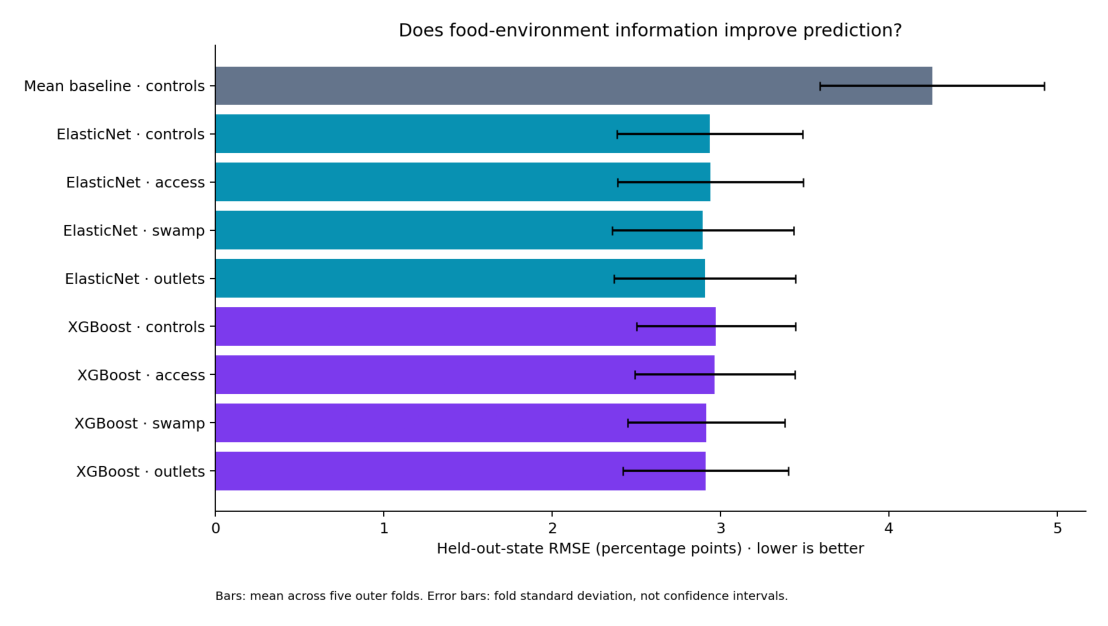

In [5]:
summary = pd.read_csv(results / "summary.csv")
print(summary[["model", "feature_set", "rmse", "mae", "r2", "fold_rmse_sd"]].round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(plt.imread(results / "model_comparison.png"))
ax.axis("off")
plt.show()

## 5. Ask whether the food features earn their place

Paired differences use the same held-out states for each model. Negative RMSE differences mean the added features improved prediction. Access alone has little incremental value in these specifications. The access-plus-swamp model improves over controls in four of five ElasticNet folds and all five XGBoost folds, but the absolute improvement is modest.

This is predictive evidence about measurements at the county level—not evidence that opening a grocery store will cause a particular change in obesity.

In [6]:
deltas = pd.read_csv(results / "paired_deltas.csv")
paired = deltas.groupby(["model", "feature_set"]).rmse_delta_vs_controls.agg(
    mean_delta="mean", best_fold="min", worst_fold="max", improved_folds=lambda x: int((x < 0).sum()))
print(paired.round(4).to_string())
coefficients = pd.read_csv(results / "elasticnet_coefficients.csv")
coef_summary = coefficients[coefficients.feature_set == "swamp"].groupby("feature").coefficient.agg(["mean", "min", "max"])
print("\nElasticNet swamp-model coefficients across outer training fits:")
print(coef_summary.sort_values("mean").round(3).to_string())

                        mean_delta  best_fold  worst_fold  improved_folds
model      feature_set                                                   
ElasticNet access           0.0047    -0.0000      0.0180               1
           outlets         -0.0284    -0.0670      0.0429               4
           swamp           -0.0396    -0.0757      0.0101               4
XGBoost    access          -0.0060    -0.0429      0.0459               3
           outlets         -0.0598    -0.0930     -0.0216               5
           swamp           -0.0564    -0.0812     -0.0224               5

ElasticNet swamp-model coefficients across outer training fits:
                   mean    min    max
feature                              
ba_plus_pct      -1.896 -1.998 -1.790
hs_plus_pct      -0.171 -0.326 -0.000
rucc_2            0.000  0.000  0.000
rucc_3            0.000 -0.000 -0.000
rucc_4            0.000  0.000  0.000
rucc_5            0.000  0.000  0.000
rucc_6            0.000  0.000  0.000
r

Coefficient ranges describe variation between fitted training folds, not inferential confidence intervals. Continuous variables are standardized within each training set; rural–urban indicators are unscaled. Coefficients are conditional, regularized associations, so their magnitude and sign can depend on the other included measurements.

## 6. Find the failures hidden by average accuracy

Error analysis uses only out-of-fold predictions. A positive bias means overprediction. The low- and high-prevalence groups are defined using the observed outcome for retrospective diagnosis, not for prospective routing of predictions. Metro/nonmetro groupings use RUCC 1–3 and 4–9.

Both models pull predictions toward the middle, missing some geographic extremes. Large state errors warrant further investigation; states with only a few counties have less stable estimates.

     model    dimension         group    n  rmse   bias
ElasticNet     rurality         Metro 1137 2.919 -0.088
ElasticNet     rurality      Nonmetro 1973 2.944  0.017
ElasticNet outcome_band        30–40% 2425 2.375 -0.041
ElasticNet outcome_band 40% or higher  404 3.733 -2.953
ElasticNet outcome_band     Below 30%  281 5.158  4.361
   XGBoost     rurality         Metro 1137 2.854 -0.043
   XGBoost     rurality      Nonmetro 1973 2.995 -0.079
   XGBoost outcome_band        30–40% 2425 2.483 -0.047
   XGBoost outcome_band 40% or higher  404 3.707 -2.811
   XGBoost outcome_band     Below 30%  281 4.792  3.715

Largest ElasticNet state errors (state FIPS identifiers):
group  n  rmse  bias
   15  4 8.062 7.962
   08 64 7.097 6.857
   06 58 5.507 5.205
   35 33 5.135 4.607
   50 14 4.580 3.986


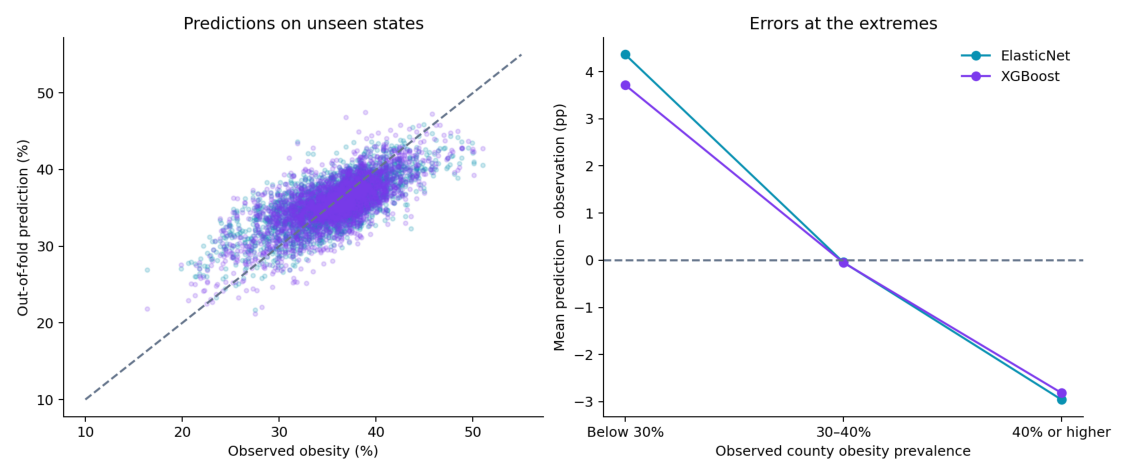

In [7]:
errors = pd.read_csv(results / "subgroup_errors.csv", dtype={"group": str})
subset = errors[(errors.feature_set == "swamp") & (errors.dimension != "state")]
print(subset[["model", "dimension", "group", "n", "rmse", "bias"]].round(3).to_string(index=False))
print("\nLargest ElasticNet state errors (state FIPS identifiers):")
state_errors = errors[(errors.feature_set == "swamp") & (errors.model == "ElasticNet") & (errors.dimension == "state")]
print(state_errors.nlargest(5, "rmse")[["group", "n", "rmse", "bias"]].round(3).to_string(index=False))
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.imshow(plt.imread(results / "error_analysis.png"))
ax.axis("off")
plt.show()

## 7. What this supports—and what comes next

The regularized linear model is competitive with the fixed tree ensemble. Food-swamp measurements contribute modest incremental predictive information, while access alone contributes little under these specifications. The size and geographic pattern of errors remain important even when overall R² is around 0.52.

The next experiments should prioritize independent geographic or temporal validation, aligned data vintages, a documented county-exclusion audit, and spatially appropriate uncertainty estimates. This dataset and design cannot identify causal policy effects or individual risk.

**Reproduce:** `python src/model.py --jobs 1`  
**Check:** `python -m unittest discover -s tests -v`  
**Audit:** `results/portfolio/run_manifest.json`, `fold_audit.json`, and `predictions.csv`.

The earlier SHAP plot belongs to the archived feature specification; it is deliberately not used to explain these revised models.